# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é que vocês apliquem os conceitos estatísticos vistos no último módulo, mais os conceitos de visualizações de dados através de gráficos e finalizem publicando no seu github!

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import plotly.io as pio

Faça a leitura dos dados do arquivo CSV:


Altere o código abaixo de acordo com seu diretório.

In [9]:
df = pd.read_csv("MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv", delimiter=',')

df.head(50)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [15]:
#Seu código aqui para a média

df.groupby('Categoria')['Preco_Normal'].mean().round(2).reset_index().sort_values(by='Preco_Normal', ascending=False)

,Categoria,Preco_Normal
1,comidas-preparadas,3095.04
5,lacteos,2385.22
2,congelados,2108.04
0,belleza-y-cuidado-personal,1783.56
3,frutas,1724.47
6,verduras,1343.30
4,instantaneos-y-sopas,765.49


In [12]:
#Seu código aqui para a mediana
df.groupby('Categoria')['Preco_Normal'].median().round(2).reset_index().sort_values(by='Preco_Normal', ascending=False)

,Categoria,Preco_Normal
1,comidas-preparadas,3290.0
0,belleza-y-cuidado-personal,1569.0
2,congelados,1519.0
3,frutas,1195.0
6,verduras,1180.0
5,lacteos,989.0
4,instantaneos-y-sopas,439.0


Digite aqui as categorias: comidas-preparadas é a unica categoria onde a média está abaixo da mediana.

# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [13]:
#Seu código aqui
desvio_padrao_por_categoria = df.groupby('Categoria')['Preco_Normal'].std().round(2).reset_index().sort_values(by='Preco_Normal', ascending=False)
desvio_padrao_por_categoria

,Categoria,Preco_Normal
5,lacteos,3925.82
0,belleza-y-cuidado-personal,2210.04
2,congelados,2111.54
1,comidas-preparadas,2019.91
3,frutas,1639.15
4,instantaneos-y-sopas,1170.23
6,verduras,1012.70


Digite nesse campo o comportamento que você identificou:

lacteos = Teve um dos maiores valores na media de preços e uma das menores em mediana,e por isso foi a categoria com o maior desvio padrão.

Comidas-preparadas = É a única categoria onde a mediana é maior que a média (Mediana: 3290 vs. Média: 3095), com um desvio padrão alto (2019,91).

# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

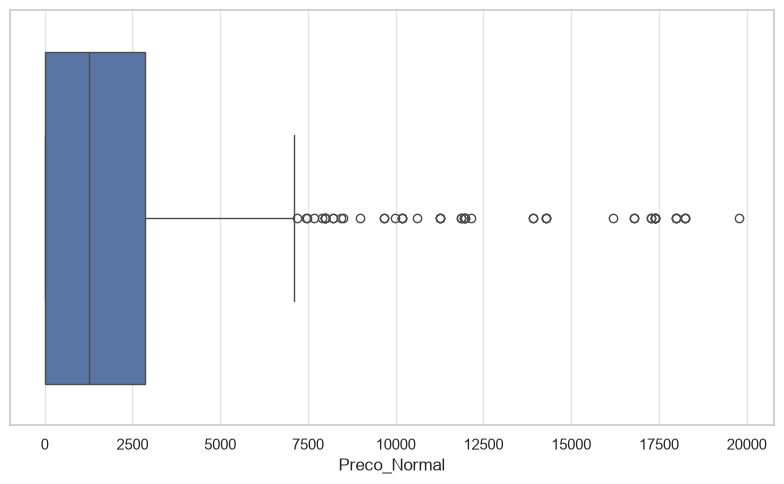

In [27]:
#A distribuição é extremamente assimétrica (com forte assimetria à direita). A imensa maioria dos produtos de lácteos tem preços baixos enquanto uma minoria puxa a escala para cima
#Cada bolinha ao lado direito representa um produto (outlier) com um preço atipicamente alto em relação ao padrão da categoria.
sns.set_theme(style="whitegrid")
df.loc[df['Categoria']=='lacteos']
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Preco_Normal')

plt.tight_layout()
plt.show()

# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

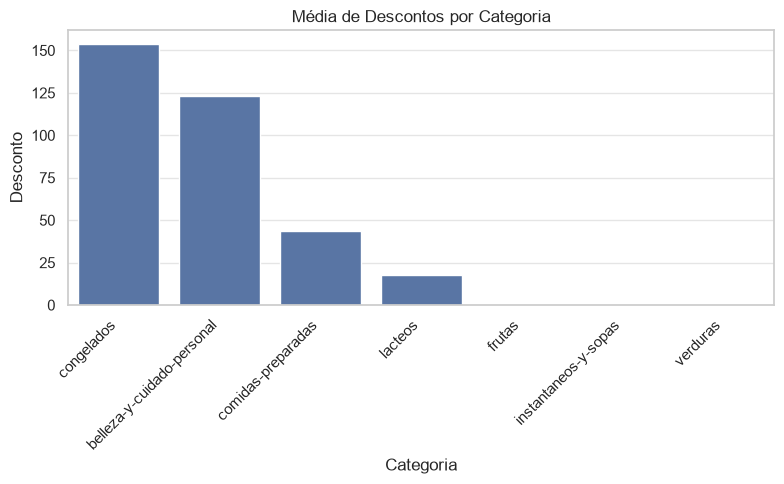

In [29]:
# Seu código aqui

media_desconto = df.groupby('Categoria')['Desconto'].mean().round(2).reset_index().sort_values(by='Desconto', ascending=False)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.barplot(
    data=media_desconto,
    x='Categoria',
    y='Desconto',
)
plt.xticks(rotation=45, ha='right')
plt.title('Média de Descontos por Categoria')
plt.tight_layout()
plt.show()

# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [57]:
# Seu código aqui
media_desconto = df.groupby(['Categoria', 'Marca'])['Desconto'].mean().round(2).reset_index().sort_values(by='Desconto', ascending=False)

fig = px.treemap(
    media_desconto,
    path=['Categoria', 'Marca'],
    values='Desconto',
    color='Desconto',
    color_continuous_scale='RdYlGn',
    title='Média de Desconto por Categoria e Marca'
)
pio.renderers.default = "browser"
fig.show()